<a href="https://colab.research.google.com/github/TildeSkar/Applied-Deep-Learning---Physics---exrecises/blob/main/Exercise_7_3_DenserNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DenserNet

Implement a DenseNet with at least two Dense Blocks, and at least three densely connected convolutional layers in each Dense Block.

Report the final test accuracy, make the standard debug plots (training accuracy vs. epochs) and plot the confusion matrix.

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tabulate import tabulate
layers = tf.keras.layers

Helper functions to visualize the results in the code below

In [ ]:
def plot_examples(X, Y, n=10):
    """ Plot the first n examples for each of the 10 classes in the CIFAR dataset X, Y """
    fig, axes = plt.subplots(n, 10, figsize=(10, n))
    for l in range(10):
        axes[0, l].set_title(cifar10_labels[l], fontsize="smaller")
        m = np.squeeze(Y) == l  # boolean mask: True for all images of label l
        for i in range(n):
            image = X[m][i].astype("uint8")  # imshow expects uint8
            ax = axes[i, l]
            ax.imshow(image, origin="upper")
            ax.set(xticks=[], yticks=[])
    return fig, ax


def plot_prediction(X, Y, Y_predict):
    """
    Plot image X along with predicted probabilities Y_predict.
    X: CIFAR image, shape = (32, 32, 3)
    Y: CIFAR label, one-hot encoded, shape = (10)
    Y_predict: predicted probabilities, shape = (10)
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

    # plot image
    ax1.imshow(X.astype("uint8"), origin="upper")
    ax1.set(xticks=[], yticks=[])

    # plot probabilities
    ax2.barh(np.arange(10), Y_predict, align="center")
    ax2.set(xlim=(0, 1), xlabel="Score", yticks=[])
    for i in range(10):
        c = "red" if (i == np.argmax(Y)) else "black"
        ax2.text(0.05, i, cifar10_labels[i].capitalize(), ha="left", va="center", color=c)



def plot_confusion(Y_true, Y_predict):
    """
    Plot confusion matrix
    Y_true:    array of true classifications (0-9), shape = (N)
    Y_predict: array of predicted classifications (0-9), shape = (N)
    """
    C = np.histogram2d(Y_true, Y_predict, bins=np.linspace(-0.5, 9.5, 11))[0]
    Cn = C / np.sum(C, axis=1)

    fig = plt.figure()
    plt.imshow(Cn, interpolation="nearest", vmin=0, vmax=1, cmap=plt.cm.YlGnBu)
    plt.colorbar()
    plt.xlabel("prediction")
    plt.ylabel("truth")
    plt.xticks(range(10), cifar10_labels, rotation="vertical")
    plt.yticks(range(10), cifar10_labels)
    for x in range(10):
        for y in range(10):
            plt.annotate("%i" % C[x, y], xy=(y, x), ha="center", va="center")


First we load and preprocess CIFAR-10 data. The imagages are 32x32 pixels and have three color channels (red, green blue).

In [ ]:
# X: images, Y: labels
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("images, shape = ", x_train.shape)
print("labels, shape = ", y_train.shape)

cifar10_labels = np.array([
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'])

images, shape =  (50000, 32, 32, 3)
labels, shape =  (50000, 1)


(<Figure size 1000x1000 with 100 Axes>, <Axes: >)

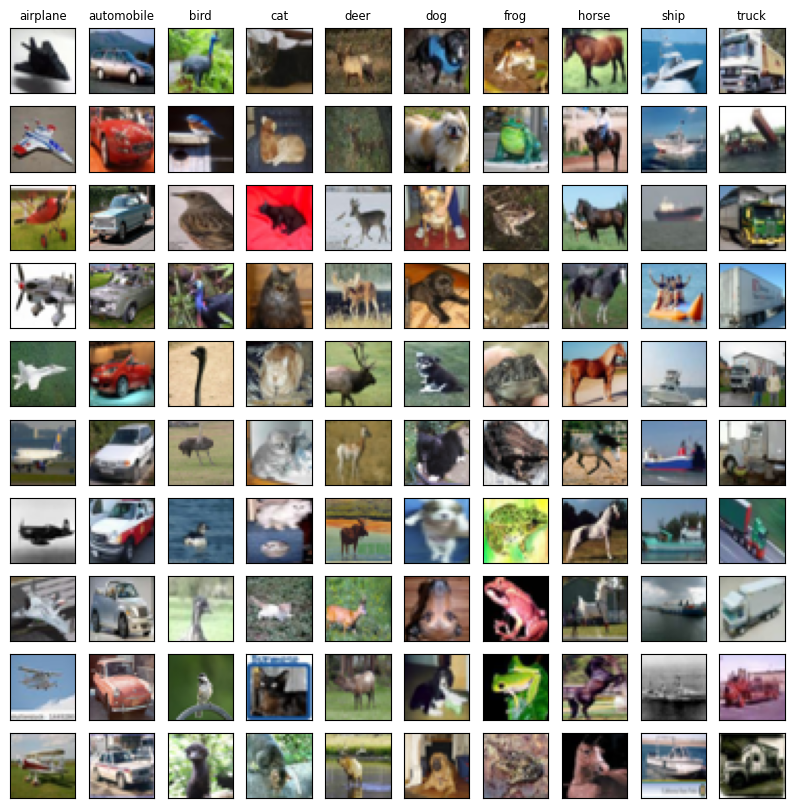

In [ ]:
# Plot example images, using the plot examples function

plot_examples(x_train, y_train)

First the data is normalised. Currently the data takes values between 0 and 255. We want to assure it can take float values between 0 and 1 instead it is thus normalized by dividing it by 255

We also use one-hot encoding for the labels. Meaning we convert the labels from 0-9 to: "0" = (1, 0, ... 0) or "1" = (0, 1, ... 0) etc.

In [ ]:
print("images, shape = ", x_test.shape)
print("labels, shape = ", y_test.shape)

images, shape =  (10000, 32, 32, 3)
labels, shape =  (10000, 1)


In [ ]:
# Convert labels to one-hot encoding
y_train_onehot = tf.keras.utils.to_categorical(y_train, 10)
y_test_onehot = tf.keras.utils.to_categorical(y_test[:8000], 10) # 80% test data
y_valid_onehot = tf.keras.utils.to_categorical(y_test[8000:], 10) # 20% validation data

# Normalize images in range (0,1)
x_train_norm = x_train.astype("float32") / 255
x_test_norm = x_test[:8000].astype("float32") / 255
x_valid_norm = x_test[8000:].astype("float32") / 255

### Densely-connected convolutions

DenseNet is a type of CNN where each layer recevies the feature map from all previous layers within the same dense block.

In normal CNN network structures each layer recives the output only from the previous layer. In DenseNet every layer resives the output from all the proceeding layers in a dense block. Dense Net is simila to ResNet but it uses concaisons instead of addition for combining the previous features. This results in diffrent levels of hirarchy being linked together.

First we create a function which creates a DenseNet block, where each convolutional layer recives the information from all previous layers

In [ ]:
# Function for constructing a dense block with 3 densely connected convolutional layers in each block.
def dense_block(x, n=5):
  """Create a block of densely connected pairs of convolutions"""
  xlist = [x] # create list for storing the output
  for i in range(n):
    # Each iteration creates an idditional convolutional layer
    # Creates 8 new feature maps, uses a 3x3 convolutional kernel, preseving image height and width
    layers.BatchNormalization() # to make training faster and more stable

    # Number of features = 12, size 3x3, paading is the same to retain the size
    x = layers.Conv2D(12, (3,3), padding='same', activation='relu')(x)
    layers.BatchNormalization() # to make training faster and more stable
    xlist.append(x) # Saves the features
    x = layers.concatenate(xlist[:], axis=-1) #Concates the features
  return x


In [ ]:
# Building the DenseNet architecture: 2 dense blocks
input_shape = (32, 32, 3) # For the CIFAR-10 library

x0 = layers.Input(shape=input_shape, name='image') # the input tesnor for the neural network
x = dense_block(x0) # Applying the first dense block
# Applying pointwise convolution, 63 to retain the size from the dense block
x = layers.Conv2D(63, (1, 1), padding='same', activation='relu')(x)
x = layers.AveragePooling2D((2,2), strides=(2,2))(x)

x = dense_block(x) # Applying the second dense block
# Applying pointwise convolution, 123 to retain the size from the dense block
x = layers.Conv2D(123, (1, 1), padding='same', activation='relu')(x)
x = layers.AveragePooling2D((2,2), strides=(2,2))(x)

x = dense_block(x)
x = layers.GlobalAveragePooling2D(name='final_globalpooling')(x)
x = layers.Dense(10, activation = 'softmax')(x) # Ten categories

model = tf.keras.models.Model(inputs=[x0], outputs=[x], name='DenseNet')
model.summary()

Model: "DenseNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 32, 32,    │        336 │ image[0][0]       │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_84      │ (None, 32, 32,    │          0 │ image[0][0],      │
│ (Concatenate)       │ 15)               │            │ conv2d_95[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_96 (Conv2D)  │ (None, 32, 32,    │      1,632 │ concatenate_84[0… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_85      │ (None, 32, 32,    │          0 │ image[0][0],      │
│ (Concatenate)       │ 27)               │            │ conv2d_95[0][0],  │
│                     │                   │            │ conv2d_96[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_97 (Conv2D)  │ (None, 32, 32,    │      2,928 │ concatenate_85[0… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_86      │ (None, 32, 32,    │          0 │ image[0][0],      │
│ (Concatenate)       │ 39)               │            │ conv2d_95[0][0],  │
│                     │                   │            │ conv2d_96[0][0],  │
│                     │                   │            │ conv2d_97[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_98 (Conv2D)  │ (None, 32, 32,    │      4,224 │ concatenate_86[0… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_87      │ (None, 32, 32,    │          0 │ image[0][0],      │
│ (Concatenate)       │ 51)               │            │ conv2d_95[0][0],  │
│                     │                   │            │ conv2d_96[0][0],  │
│                     │                   │            │ conv2d_97[0][0],  │
│                     │                   │            │ conv2d_98[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_99 (Conv2D)  │ (None, 32, 32,    │      5,520 │ concatenate_87[0… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_88      │ (None, 32, 32,    │          0 │ image[0][0],      │
│ (Concatenate)       │ 63)               │            │ conv2d_95[0][0],  │
│                     │                   │            │ conv2d_96[0][0],  │
│                     │                   │            │ conv2d_97[0][0],  │
│                     │                   │            │ conv2d_98[0][0],  │
│                     │                   │            │ conv2d_99[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_100 (Conv2D) │ (None, 32, 32,    │      4,032 │ concatenate_88[0… │
│                     │ 63)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_… │ (None, 16, 16,    │          0 │ conv2d_100[0][0]  │
│ (AveragePooling2D)  │ 63)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_101 (Conv2D) │ (None, 16, 16,    │      6,816 │ average_pooling2

 Total params: 162,244 (633.77 KB)

 Trainable params: 162,244 (633.77 KB)

 Non-trainable params: 0 (0.00 B)

### Structure

- Input
- Convolution
- Dense Block 1
- Convolution
- Pooling
- Dense block 2
- Pooling
- Linear
- Prediction

### Concepts

1x1 convolution - Pointwise convolution: Combines the information across channels without changing the spatial dimensions. Also known as a bottelneck layer. It merges diffrent features together.

Averge pooling - reduces the spatial dimensions of the feature maps. With a pool size of (2,2) it takes the avredge of each 2x2 region, while stride (2,2) moves the window 2 pixels at a time.



In [ ]:
# ----------------------------------------------------------
# Training
# ----------------------------------------------------------
model.compile(
    loss = 'categorical_crossentropy',
    optimizer = 'adam',
    metrics=['accuracy']
)

model.fit(
    x_train_norm, y_train_onehot,
    batch_size= 256,
    epochs=30, # train at least for 20 epochs
    verbose=2,
    validation_data=(x_valid_norm, y_valid_onehot),
    callbacks=[tf.keras.callbacks.CSVLogger("history_{}.csv".format(model.name))],
)

Epoch 1/30
196/196 - 29s - 146ms/step - accuracy: 0.7512 - loss: 0.7046 - val_accuracy: 0.7390 - val_loss: 0.7551
Epoch 2/30
196/196 - 11s - 56ms/step - accuracy: 0.7653 - loss: 0.6651 - val_accuracy: 0.7335 - val_loss: 0.7220
Epoch 3/30
196/196 - 11s - 56ms/step - accuracy: 0.7652 - loss: 0.6593 - val_accuracy: 0.7505 - val_loss: 0.6838
Epoch 4/30
196/196 - 20s - 102ms/step - accuracy: 0.7751 - loss: 0.6403 - val_accuracy: 0.7545 - val_loss: 0.6851
Epoch 5/30
196/196 - 11s - 54ms/step - accuracy: 0.7811 - loss: 0.6242 - val_accuracy: 0.7520 - val_loss: 0.6831
Epoch 6/30
196/196 - 11s - 54ms/step - accuracy: 0.7850 - loss: 0.6089 - val_accuracy: 0.7515 - val_loss: 0.7028
Epoch 7/30
196/196 - 11s - 55ms/step - accuracy: 0.7920 - loss: 0.5927 - val_accuracy: 0.7730 - val_loss: 0.6472
Epoch 8/30
196/196 - 10s - 53ms/step - accuracy: 0.8005 - loss: 0.5700 - val_accuracy: 0.7560 - val_loss: 0.6811
Epoch 9/30
196/196 - 10s - 53ms/step - accuracy: 0.8015 - loss: 0.5695 - val_accuracy: 0.7790 

In [ ]:
history = np.genfromtxt("history_{}.csv".format(model.name), delimiter=",", names=True)

# Here we quote the achived accuracy on the training, validation and test data sets
train_loss, train_acc = model.evaluate(x_train_norm, y_train_onehot, verbose=0)
valid_loss, valid_acc = model.evaluate(x_valid_norm, y_valid_onehot, verbose=0)
test_loss, test_acc = model.evaluate(x_test_norm, y_test_onehot, verbose=0)

print(f'Training accuracy: {train_acc}, Training loss: {train_loss}')
print(f'Validation accuracy: {valid_acc}, Validation loss: {valid_loss}')
print(f'Test accuracy: {test_acc}, Test loss: {test_loss}')

Training accuracy: 0.885420024394989, Training loss: 0.3254130780696869
Validation accuracy: 0.8015000224113464, Validation loss: 0.6158115863800049
Test accuracy: 0.8033750057220459, Test loss: 0.6181085705757141


63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step


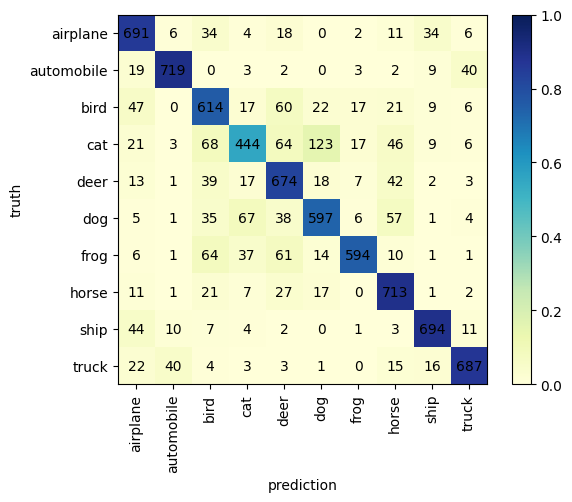

In [ ]:
# ----------------------------------------------------------
# Plots
# ----------------------------------------------------------
# training curves
history = np.genfromtxt("history_{}.csv".format(model.name), delimiter=",", names=True)


# Plot the confusion matrix for the test data set.
# calculate predictions for test set
y_predict = model.predict(x_test_norm, batch_size=128)

# convert back to class labels (0-9)
y_predict_cl = np.argmax(y_predict, axis=1)
y_test_cl = np.argmax(y_test_onehot, axis=1)

# plot confusion matrix
plot_confusion(y_test_cl, y_predict_cl)

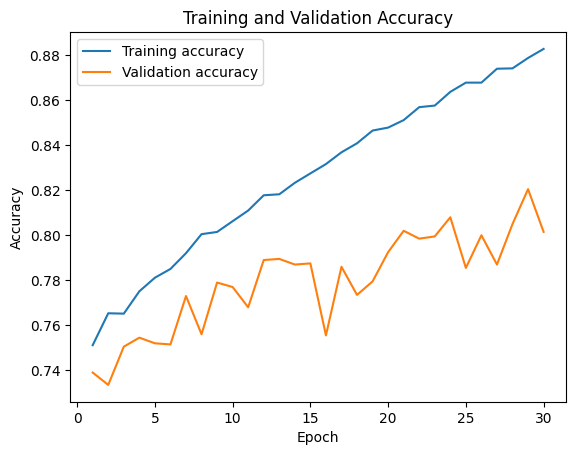

In [ ]:
# Plotting the training and validation accuracy vs epoch
epochs = range(1, len(history['accuracy']) + 1) # assure plot starts on epoch 1 and not 0

plt.plot(epochs, history['accuracy'], label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

### Training 1

Initially I started with the structure for constructing a DenseNet given by the lecture notes. However I discovered some modification from this network had to be done.

For one I changed number of features from 8 to 12 in the dense block, this sence I wanted to increase the complexity of the model.

Secondly I added added Batch Normalization in the denseBlock. Batch normalization is known to make training faster and more stable while the reason for this is unknown. It is added as a layer, however typically before the activation

For the depth of the dense block I let it start with n_layers = 5. First only 2 dense blocks where added to the DenseNet. The obtained accuracy is presented below and was approximately 0.64. Thus I wanted to investigate adding more dense_blocks to my network and see how the performance of the model changed.


Training accuracy: 0.6565799713134766, Training loss: 0.983950138092041

Validation accuracy: 0.6284999847412109, Validation loss: 1.045860767364502

Test accuracy: 0.6383749842643738, Test loss: 1.0113112926483154


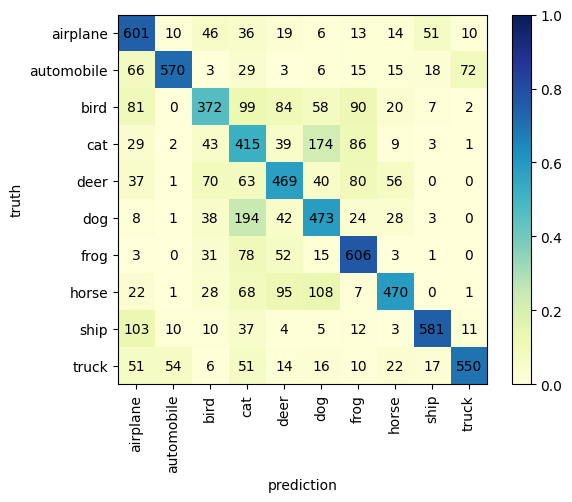

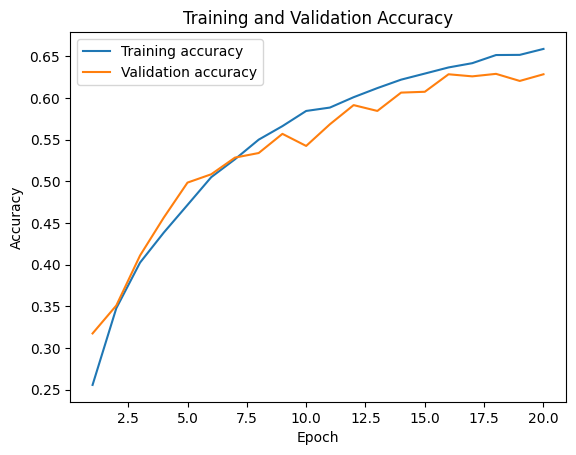

### Training 2

In the second training I extended the DenseNet by including another dense block. Thus currently the network containes 3 dense block where each block consists of 5 densly connected convolutional layers.

As shown in the results below extending the network to contain another dense block increased the accuracy to 0.72.

According to the confusion matrix the model predicts the right category for most of the time however some confussion exists regarding categorization of dogs which sometimes gets missclassified as a cat.

We can also see that the traing improves for each epoch.

Training accuracy: 0.749459981918335, Training loss: 0.7024795413017273

Validation accuracy: 0.7129999995231628, Validation loss: 0.7714062929153442

Test accuracy: 0.7223749756813049, Test loss: 0.7754464149475098

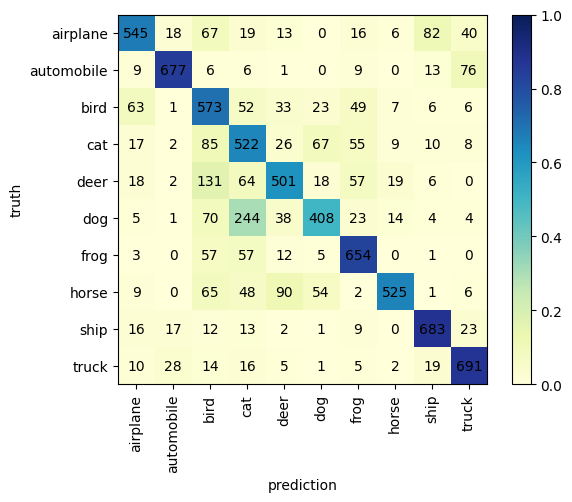

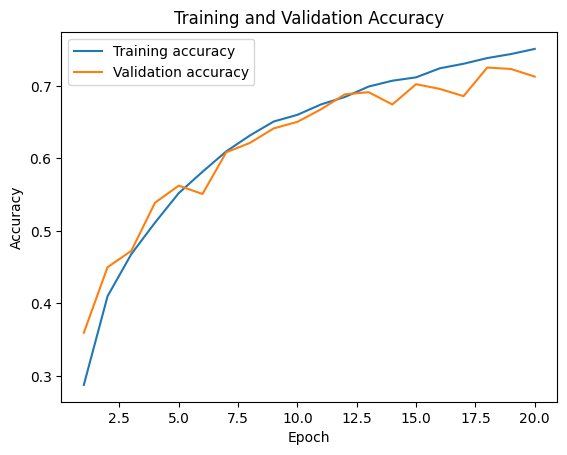

### Increasing number of epochs

I wanted to investigate if accuracy could be increase by simply letting the model run for more epochs, since it seemed from the graph above that the accuracy could still improve.

For 30 epochs the test accuracy was 0.80, see below.

Training accuracy: 0.885420024394989, Training loss: 0.3254130780696869

Validation accuracy: 0.8015000224113464, Validation loss: 0.6158115863800049

Test accuracy: 0.8033750057220459, Test loss: 0.6181085705757141

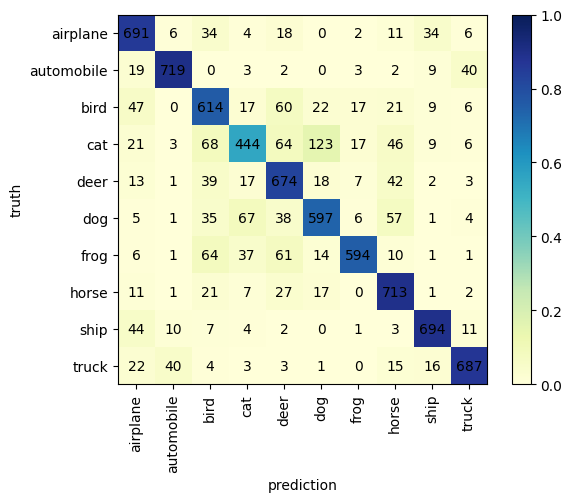

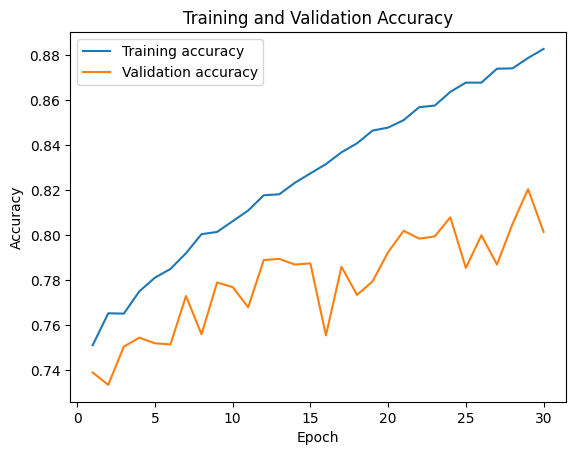

### Improvements

When increasing the depth of the network, bothe in the number of dense convolutional layers and the number of dense blocks the test accuracy improves. Also when the network was trained for longer accuracy improved. Thus in the future if I would wish to improve my model even further I would extend the depth of my netowk futer. I would add more deep convolutional layer and add more blocks. This is possible since the training was currently not that time consuming especially when using multiple processors. These improvements could hopefullt improve accuracy even further.  